# Etapa 8. Grafo de dominio (grafo de co-compra, PageRank y detección de comunidades)

Proyecto EDA 2026-2 · Grupo 1 · Escenario B (comercio electrónico)
Responsable de la etapa 8: Jesús.

Esta etapa modela la red de relaciones de co-compra entre los productos del catálogo de Amazon Reviews 2023 (`Office_Products`). Construye un grafo no dirigido y ponderado en representación **CSR** (*Compressed Sparse Row*) a partir de las órdenes con varios productos del stream procesado en la etapa 2, sin las órdenes bloqueadas por la etapa 6. Sobre esta topología se implementan y evalúan dos familias algorítmicas de análisis de grafos:

1. **Centralidad e influencia:** **PageRank** con iteración de potencias vectorizada (*Power Iteration* con SpMV sobre CSR) frente a la línea base de **grado ponderado**.
2. **Detección de comunidades:** **Louvain multinivel**, que optimiza la modularidad de Newman-Girvan, frente a la línea base de **Label Propagation (LPA)**.

Las dos implementaciones se contrastan con la biblioteca **NetworkX** en tiempo, memoria (`tracemalloc`) y calidad, y las comunidades se comparan también por su estabilidad entre semillas.

## Función de la etapa en el pipeline

| Entrada | Origen | Uso |
| --- | --- | --- |
| `etapa2_eventos.jsonl` | Etapa 2 | Compras en orden de servicio; cada orden con dos o más productos aporta aristas |
| `etapa_6/ordenes_bloqueadas.json` | Etapa 6 | Órdenes de fraude que no entran al grafo |
| `etapa_3/catalogo.jsonl` y `AlmacenCatalogo` | Etapa 3 | Título, categoría y precio de los productos para inspeccionar los resultados |
| `TablaHash` | Etapa 3 | Posición de cada `parent_asin` en el CSR |

**Salidas para la etapa 9.** `grafo_cocompra.npz` (señal S_co del scoring), `pagerank.parquet` (S_pr), `comunidades.parquet` y `metricas.json`, en `data/interim/<CATEGORIA>/etapa_8/`.

**Alcance del grafo de co-compra.** Las co-compras salen del generador sintético de la etapa 0: una orden agrega de 1 a 3 productos del mismo grupo `crc32(asin) % 500`, sin relación con el producto. Por eso las comunidades de este grafo son los grupos del generador y no temas del catálogo. El paso 10 lo verifica y valida los algoritmos con una señal real, el grafo de co-reseñas de las 12.8 M reseñas del dataset.

## Proceso

```
etapa2_eventos.jsonl (etapa 2) − órdenes bloqueadas (etapa 6)
   │
   ├─ 1. órdenes legítimas con 2 o más productos → pares (u, v) y su número de órdenes
   ├─ 2. CSR simétrico: indptr, indices, data                                         O(|V| + |E|)
   ├─ 3. PageRank (una SpMV por iteración) y grado ponderado                          O(k · |E|)
   └─ 4. Louvain y LPA, con las comunidades desconectadas partidas en sus componentes  ≈ O(|E|) por pasada
   │
grafo_cocompra.npz · pagerank.parquet · comunidades.parquet · metricas.json (etapa 9)
```

## Pasos del notebook

1. Configuración y entrada.
2. Grafo de co-compra y topología.
3. Centralidad e influencia: PageRank.
4. Detección de comunidades: Louvain.
5. Línea base: Label Propagation.
6. Elección de parámetros.
7. Resultados en el pipeline e inspección cualitativa.
8. Salidas de la etapa 8.
9. Experimentos de escalabilidad.
10. Auditoría técnica, validación con datos reales y estabilidad.

## Paso 1. Configuración y entrada

El código de la etapa está en `src/etapa_8/`: `graph.py` (estructura y algoritmos), `benchmark.py` (experimentos de los pasos 2, 6, 9 y 10), `escala_stream.py` (escala medida sobre el stream real, paso 9.4) y `grafo_resenas_reales.py` (grafo de co-reseñas del paso 10). La salida se guarda en `data/interim/<CATEGORIA>/etapa_8/` y los resultados de los experimentos en `results/etapa_8/`.

Los experimentos se reutilizan si sus resultados existen y tienen las columnas de la versión actual del experimento; si no, se miden de nuevo. Para medir todo otra vez se cambia `REEJECUTAR_EXPERIMENTOS` a `True` en la celda siguiente. Cada tabla de resultados guarda el procesador y la versión de Python con que se midió. La categoría y la semilla salen de `src/config.py`.

In [1]:
import json
import platform
import sys
import time
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config
from src.etapa_3.storage import RUTA_CATALOGO, RUTA_EVENTOS_ETAPA2, AlmacenCatalogo
from src.etapa_6.probabilistic import RUTA_BLOQUEADAS
from src.etapa_8 import benchmark, escala_stream
from src.etapa_8 import grafo_resenas_reales as resenas
from src.etapa_8.graph import (
    ALPHA, MAX_ITER_PAGERANK, RUTA_COMUNIDADES, RUTA_GRAFO, RUTA_METRICAS, RUTA_PAGERANK, TOL_PAGERANK,
    GrafoCoCompra, componentes_conexas, dividir_comunidades_desconectadas, ejecutar_etapa,
    grado_ponderado_ranking, label_propagation, louvain, modularidad, pagerank,
)

CATEGORIA = config.CATEGORIA
SEED = config.SEED
RUTA_EVENTOS = RUTA_EVENTOS_ETAPA2
RUTA_BLOQUEADOS = RUTA_BLOQUEADAS
DIR_RESULTADOS = config.CARPETA_RESULTADOS / "etapa_8"
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
assert RUTA_EVENTOS.exists(), "Falta la salida de la etapa 2. Ejecutar antes notebooks/etapa2_cola_prioridades.ipynb"
assert RUTA_BLOQUEADOS.exists(), "Falta la salida de la etapa 6. Ejecutar antes notebooks/etapa6_filtrado_probabilistico.ipynb"

# Plataforma (el enunciado pide reportarla junto con la semilla)
PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor() or platform.machine(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}
print(f"Categoría: {CATEGORIA}   semilla: {SEED}")
PLATAFORMA

Categoría: Office_Products   semilla: 42


{'sistema': 'Windows-10-10.0.19045-SP0',
 'procesador': 'AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD',
 'nucleos': 8,
 'ram_gb': 32.1,
 'python': '3.12.0',
 'semilla': 42}

In [2]:
# Protocolo de persistencia y reutilización de mediciones
# Las mediciones guardadas en results/etapa_8/ se reutilizan. Con True se miden de nuevo.
REEJECUTAR_EXPERIMENTOS = False
R = DIR_RESULTADOS


def resultados(ruta, medir_tabla, requeridas=()):
    """Lee la tabla de resultados si existe y tiene las columnas `requeridas`. Si no, la mide con
    medir_tabla() y la guarda con la plataforma."""
    if ruta.exists() and not REEJECUTAR_EXPERIMENTOS:
        tabla = pd.read_csv(ruta, dtype={"procesador": str, "python": str})
        if all(c in tabla.columns for c in requeridas):
            print(f"Resultados leídos de {ruta.name}")
            return tabla
        print(f"{ruta.name} es de una versión anterior del experimento y se mide de nuevo")
    tabla = medir_tabla().assign(procesador=PLATAFORMA["procesador"], python=PLATAFORMA["python"])
    tabla.to_csv(ruta, index=False)
    print(f"Resultados guardados en {ruta.name}")
    return tabla


def resultados_archivos(rutas, ejecutar, vigente=lambda: True):
    """Reutiliza los archivos que escribe un script de src/etapa_8/ si existen y están vigentes;
    si no, ejecuta el script."""
    if not REEJECUTAR_EXPERIMENTOS and all(r.exists() for r in rutas) and vigente():
        print("Resultados leídos de", ", ".join(r.name for r in rutas))
        return
    ejecutar()
    print("Resultados guardados en", ", ".join(r.name for r in rutas))


def plataforma_de(tabla):
    """Procesador y versión de Python con que se midió una tabla de resultados."""
    if "procesador" in tabla.columns and "python" in tabla.columns:
        return f"{tabla['procesador'].iloc[0]}, Python {tabla['python'].iloc[0]}"
    return f"{PLATAFORMA['procesador']}, Python {PLATAFORMA['python']}"

## Paso 2. Grafo de co-compra y topología

El grafo de co-compra $G = (V, E, W)$ modela la canasta de compra (*market basket analysis*):
- Los vértices $V$ son los productos, identificados por su `parent_asin`.
- Una arista $(u, v) \in E$ con peso $w_{uv} \in \mathbb{N}_{\ge 1}$ indica que $u$ y $v$ se compraron juntos en $w_{uv}$ órdenes distintas.
- **Exclusión de fraude (etapa 6):** las compras de las órdenes bloqueadas por la etapa 6 no entran al grafo, para que el fraude no cree co-compras. La celda 2.3 mide cuánto cambia el grafo con esa exclusión.
- **Representación en memoria (CSR):** matriz dispersa simétrica con punteros de fila `indptr`, columnas `indices` y pesos `data`, que ocupa $O(|V| + |E|)$ sin un objeto de Python por arista.

`ejecutar_etapa` recorre el stream una vez, construye el grafo, calcula PageRank y las comunidades con los parámetros de `src/etapa_8/graph.py` y escribe las cuatro salidas de la etapa. Las celdas siguientes cargan el grafo guardado para describirlo.

In [3]:
# 2.1 Construcción del grafo y salidas de la etapa
metricas = ejecutar_etapa()
grafo = GrafoCoCompra.cargar_npz(RUTA_GRAFO)

n = grafo.n
m_aristas = grafo.m
w_total = grafo.peso_total
grados = grafo.grados
grados_ponderados = grafo.grados_ponderados()

print(f"Compras procesadas: {metricas['grafo']['compras_procesadas']:,}; "
      f"compras de órdenes bloqueadas excluidas: {metricas['grafo']['compras_bloqueadas_excluidas']:,}")
print(f"Órdenes legítimas: {metricas['grafo']['ordenes_legitimas']:,}; "
      f"con dos o más productos: {metricas['grafo']['ordenes_con_cocompra']:,}")
print(f"Vértices (|V|): {n:,}")
print(f"Aristas no dirigidas (|E|): {m_aristas:,}")
print(f"Entradas no nulas en CSR: {len(grafo.indices):,}")
print(f"Suma total de pesos (m): {w_total:,.1f}")
print(f"Grado promedio: {np.mean(grados):.2f}")
print(f"Grado máximo: {np.max(grados):,} (ponderado: {np.max(grados_ponderados):,.0f})")
print(f"Densidad de la red: {2 * m_aristas / (n * (n - 1)):.8f}")
print(f"Etapa ejecutada en {metricas['segundos_total']:.1f} s")

Compras procesadas: 1,978,936; compras de órdenes bloqueadas excluidas: 31,878
Órdenes legítimas: 1,303,414; con dos o más productos: 324,550
Vértices (|V|): 150,534
Aristas no dirigidas (|E|): 805,587
Entradas no nulas en CSR: 1,611,174
Suma total de pesos (m): 1,067,474.0
Grado promedio: 10.70
Grado máximo: 279 (ponderado: 1,606)
Densidad de la red: 0.00007110
Etapa ejecutada en 99.0 s


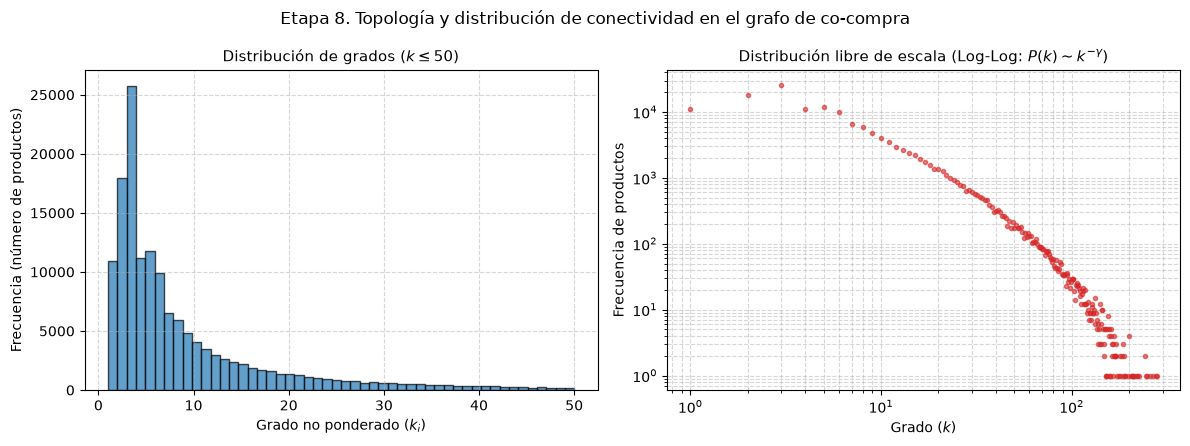

In [4]:
# 2.2 Distribución de grados (red libre de escala)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Histograma de grados (escala lineal con límite)
axes[0].hist(grados[grados <= 50], bins=50, color="#1f77b4", edgecolor="black", alpha=0.7)
axes[0].set_title(r"Distribución de grados ($k \leq 50$)", fontsize=11)
axes[0].set_xlabel("Grado no ponderado ($k_i$)", fontsize=10)
axes[0].set_ylabel("Frecuencia (número de productos)", fontsize=10)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Distribución en escala log-log
grados_pos = grados[grados > 0]
k_vals, counts = np.unique(grados_pos, return_counts=True)
axes[1].loglog(k_vals, counts, "o", color="#d62728", markersize=3, alpha=0.6)
axes[1].set_title(r"Distribución libre de escala (Log-Log: $P(k) \sim k^{-\gamma}$)", fontsize=11)
axes[1].set_xlabel("Grado ($k$)", fontsize=10)
axes[1].set_ylabel("Frecuencia de productos", fontsize=10)
axes[1].grid(True, which="both", linestyle="--", alpha=0.5)

fig.suptitle("Etapa 8. Topología y distribución de conectividad en el grafo de co-compra", fontsize=12)
fig.tight_layout()
fig.savefig(R / "distribucion_grados.png", dpi=150)
plt.show()

### Efecto de la exclusión de las órdenes bloqueadas por la etapa 6

`benchmark.efecto_exclusion_etapa6` construye el grafo dos veces, con las órdenes bloqueadas por la etapa 6 excluidas y sin excluirlas, y compara nodos, aristas y pesos. Una orden solo aporta aristas si tiene dos o más productos distintos, así que la tabla también cuenta cuántas órdenes bloqueadas cumplen esa condición. Así se verifica si la integración de la etapa 6 con la 8 tiene un efecto observable en el grafo.

In [5]:
# 2.3 Grafo con y sin la exclusión de la etapa 6
exclusion = resultados(R / "exclusion_etapa6.csv", benchmark.efecto_exclusion_etapa6)
display(exclusion.drop(columns=["procesador", "python"]).T.rename(columns={0: "valor"}))
fila = exclusion.iloc[0]
print(f"Órdenes bloqueadas con dos o más productos: {int(fila['ordenes_bloqueadas_con_cocompra']):,} "
      f"de {int(fila['ordenes_bloqueadas_excluidas']):,}")
print(f"Aristas que solo existen sin la exclusión: {int(fila['aristas_solo_sin_exclusion']):,}; "
      f"aristas comunes con otro peso: {int(fila['aristas_con_peso_distinto']):,}")

Resultados guardados en exclusion_etapa6.csv


,valor
compras_bloqueadas_excluidas,31878.0
ordenes_bloqueadas_excluidas,31878.0
ordenes_bloqueadas_con_cocompra,0.0
nodos_con_exclusion,150534.0
nodos_sin_exclusion,150534.0
aristas_con_exclusion,805587.0
aristas_sin_exclusion,805587.0
peso_con_exclusion,1067474.0
peso_sin_exclusion,1067474.0
nodos_solo_sin_exclusion,0.0


Órdenes bloqueadas con dos o más productos: 0 de 31,878
Aristas que solo existen sin la exclusión: 0; aristas comunes con otro peso: 0


## Paso 3. Centralidad e influencia: PageRank

El algoritmo **PageRank** (Brin y Page, 1998) modela un paseo aleatorio con reinicio sobre la red de co-compras:
- Con probabilidad $\alpha$ (factor de amortiguamiento, típicamente $0.85$), el navegante sigue una arista proporcional al peso de co-compra $P_{ij} = \frac{w_{ij}}{k_i}$.
- Con probabilidad $1 - \alpha$, salta uniformemente a cualquier nodo de la red.
- Los nodos colgantes (*dangling nodes*, con $k_i = 0$) redistribuyen su masa de probabilidad equitativamente entre todos los nodos. En este grafo no hay ninguno, porque solo entran productos con al menos una co-compra; la fórmula los contempla para cualquier grafo:
  $$p_{t+1} = \alpha P^T p_t + \left( \alpha \frac{\sum_{j \in \text{Dangling}} p_t(j)}{n} + \frac{1 - \alpha}{n} \right) \mathbf{1}$$

La multiplicación matriz-vector dispersa (SpMV) se resuelve de forma vectorizada en $O(|E|)$ mediante `np.bincount`, con convergencia geométrica $\|p_{t+1} - p_t\|_1 < \epsilon$ en pocas iteraciones.

**Complejidad.** Cada iteración cuesta $O(|V| + |E|)$ y el número de iteraciones es $O(\log(1/\epsilon) / \log(1/\alpha))$: con $\alpha = 0.85$ y $\epsilon = 10^{-6}$ bastan unas decenas. La memoria adicional es $O(|V|)$, además del CSR. El grado ponderado cuesta $O(|V| + |E|)$ una sola vez.

**Casos de uso, límites y compromisos.** PageRank mide influencia global: un producto pesa más si está conectado con productos que a su vez son centrales. En un grafo **no dirigido**, sin el salto aleatorio, el estado estacionario es exactamente $k_i / 2m$, así que PageRank se separa poco del grado; el paso 10 mide esa correlación. En la etapa 9 es la autoridad del producto (S_pr). Un $\alpha$ mayor da más peso a la estructura y necesita más iteraciones; uno menor acerca el resultado a la distribución uniforme.

In [6]:
# 3.1 Ejecución de PageRank frente al grado ponderado (una ejecución; el paso 9 mide con repeticiones)
t0 = time.perf_counter()
pr_scores, iter_pr, conv_pr = pagerank(grafo, alpha=ALPHA, tol=TOL_PAGERANK, max_iter=MAX_ITER_PAGERANK)
t_pr = time.perf_counter() - t0

t0 = time.perf_counter()
grado_scores = grado_ponderado_ranking(grafo)
t_grado = time.perf_counter() - t0

print(f"PageRank convergió: {conv_pr}, en {iter_pr} iteraciones ({t_pr * 1000:.2f} ms)")
print(f"Grado ponderado calculado en {t_grado * 1000:.2f} ms")
print(f"Suma de PageRank: {np.sum(pr_scores):.6f} (normalizado)")
print(f"Score del producto top 1: {np.max(pr_scores):.6f}")
print(f"Nodos colgantes (grado 0): {int((grados == 0).sum())}")

PageRank convergió: True, en 25 iteraciones (487.75 ms)
Grado ponderado calculado en 0.80 ms
Suma de PageRank: 1.000000 (normalizado)
Score del producto top 1: 0.000396
Nodos colgantes (grado 0): 0


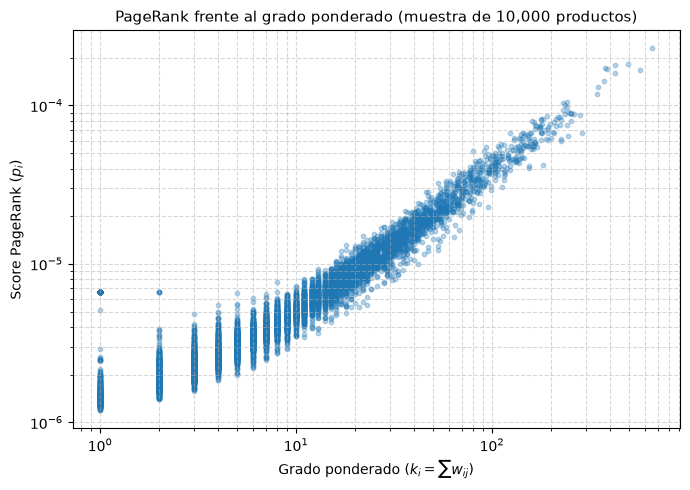

In [7]:
# 3.2 Correlación y contraste: PageRank frente al grado ponderado
idx_sample = np.random.default_rng(SEED).choice(n, size=min(10_000, n), replace=False)

fig = plt.figure(figsize=(7, 5))
plt.scatter(grados_ponderados[idx_sample], pr_scores[idx_sample], alpha=0.3, s=10, c="#1f77b4")
plt.xscale("log")
plt.yscale("log")
plt.title(f"PageRank frente al grado ponderado (muestra de {len(idx_sample):,} productos)", fontsize=11)
plt.xlabel(r"Grado ponderado ($k_i = \sum w_{ij}$)", fontsize=10)
plt.ylabel("Score PageRank ($p_i$)", fontsize=10)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
fig.savefig(R / "pagerank_vs_grado.png", dpi=150)
plt.show()

## Paso 4. Detección de comunidades: algoritmo de Louvain

El algoritmo de **Louvain** (Blondel et al., 2008) busca una partición $\mathcal{C} = \{C_1, C_2, \dots, C_k\}$ de los productos que maximice la **modularidad de Newman-Girvan** (Newman, 2006):
$$Q = \frac{1}{2m} \sum_{ij} \left( A_{ij} - \gamma \frac{k_i k_j}{2m} \right) \delta(c_i, c_j)$$

donde $2m = \sum_{ij} A_{ij}$, $k_i = \sum_j A_{ij}$, y $\gamma$ es el parámetro de resolución.

Louvain opera en dos fases iterativas:
1. **Fase 1 (Optimización codiciosa local):** Cada nodo se traslada a la comunidad vecina que maximice la ganancia local de modularidad:
   $$\Delta Q = \frac{k_{i, in}}{2m} - \gamma \frac{k_i \Sigma_{tot}}{2m^2}$$
   donde $k_{i, in}$ es el peso de las aristas de $i$ hacia la comunidad objetivo, y $\Sigma_{tot}$ es la suma de los grados de dicha comunidad.
2. **Fase 2 (Contracción multinivel):** Las comunidades identificadas se agrupan en super-vértices, sumando los enlaces internos como bucles propios (*self-loops*) y los enlaces externos como aristas ponderadas entre super-vértices.

El proceso se repite jerárquicamente hasta que ninguna reasignación aumente la modularidad.

**Complejidad.** Cada pasada de la fase 1 recorre todas las aristas, $O(|E|)$, y en la práctica bastan pocas pasadas y pocos niveles; la contracción cuesta $O(|E|)$ por nivel. La implementación guarda la adyacencia de cada nivel en diccionarios de Python, varias veces la memoria del CSR (paso 9). Las comunidades que quedan internamente desconectadas se parten en sus componentes con `dividir_comunidades_desconectadas`, en $O(|V| + |E|)$ y sin bajar $Q$, que es la garantía que da Leiden (Traag, Waltman y van Eck, 2019).

**Casos de uso, límites y compromisos.** Louvain agrupa productos que se compran juntos más de lo que predice el azar, útil para recomendar dentro de un grupo o para segmentar el catálogo. Su límite conocido es la **resolución**: con $\gamma = 1$ no separa comunidades más pequeñas que $\sqrt{2m}$ aproximadamente (Fortunato y Barthélemy, 2007). El resultado depende del orden en que visita los nodos, así que el paso 10 mide su estabilidad con varias semillas. Si el grafo está formado por componentes conexas pequeñas y densas, como este, la partición de máxima modularidad coincide con las componentes.

In [8]:
# 4.1 Ejecución de Louvain multinivel
t0 = time.perf_counter()
comunidades_louvain, mod_louvain, niveles_louvain = louvain(grafo, resolucion=1.0, max_niveles=10, semilla=SEED)
t_louvain = time.perf_counter() - t0

conteo_louvain = pd.Series(comunidades_louvain).value_counts()

print(f"Louvain finalizado en {t_louvain:.2f} s")
print(f"Niveles jerárquicos alcanzados: {niveles_louvain}")
print(f"Modularidad Newman-Girvan (Q): {mod_louvain:.6f}")
print(f"Número de comunidades detectadas: {len(conteo_louvain):,}")
print(f"Tamaño comunidad más grande: {conteo_louvain.iloc[0]:,} productos")
print(f"Mediana de tamaño de comunidad: {conteo_louvain.median():.1f} productos")


Louvain finalizado en 14.43 s
Niveles jerárquicos alcanzados: 3
Modularidad Newman-Girvan (Q): 0.997920
Número de comunidades detectadas: 841
Tamaño comunidad más grande: 356 productos
Mediana de tamaño de comunidad: 282.0 productos


## Paso 5. Línea base: Label Propagation Algorithm (LPA)

Como contraste algorítmico, implementamos el algoritmo de propagación de etiquetas (**LPA**, Raghavan et al., 2007):
- Cada nodo inicia con su propia etiqueta identificadora.
- En cada iteración asíncrona, los nodos se visitan en orden aleatorio y adoptan la etiqueta que acumule el mayor peso total entre sus vecinos:
  $$c_i \leftarrow \arg\max_c \sum_{j \in N(i), c_j = c} w_{ij}$$
- LPA es extremadamente rápido ($O(|E|)$ por ronda) y no requiere optimizar una función objetivo global, pero puede sufrir de oscilaciones y formación de componentes dominantes gigantes sin resolución ajustable.

**Casos de uso, límites y compromisos.** LPA no optimiza una función objetivo: es una línea base rápida. Su resultado depende del orden de visita y de los desempates, y no tiene un parámetro de resolución. Como en Louvain, sus comunidades desconectadas se parten en componentes. El paso 10 compara la estabilidad de los dos algoritmos.

In [9]:
# 5.1 Ejecución de LPA
t0 = time.perf_counter()
comunidades_lpa, iter_lpa, mod_lpa = label_propagation(grafo, max_iter=30, semilla=SEED)
t_lpa = time.perf_counter() - t0

conteo_lpa = pd.Series(comunidades_lpa).value_counts()

print(f"LPA finalizado en {t_lpa:.2f} s")
print(f"Iteraciones hasta converger: {iter_lpa}")
print(f"Modularidad alcanzada (Q): {mod_lpa:.6f}")
print(f"Número de comunidades detectadas: {len(conteo_lpa):,}")
print(f"Tamaño comunidad más grande: {conteo_lpa.iloc[0]:,} productos")


LPA finalizado en 11.69 s
Iteraciones hasta converger: 11
Modularidad alcanzada (Q): 0.995856
Número de comunidades detectadas: 1,712
Tamaño comunidad más grande: 356 productos


## Paso 6. Elección de parámetros

Analizamos las grillas de hiperparámetros sobre los datos reales:
1. **Factor de amortiguamiento $\alpha$ de PageRank:** $\alpha \in \{0.70, 0.75, 0.80, 0.85, 0.90, 0.95\}$.
2. **Parámetro de resolución $\gamma$ de Louvain:** $\gamma \in \{0.5, 1, 2, 5, 10, 20\}$ sobre el grafo completo, contrastado con sus componentes conexas (auditoría 2026-10-27: la grilla anterior usaba un subgrafo de 10 000 nodos casi sin aristas y daba 8 488 comunidades de mediana 1 para todo $\gamma$).

Las grillas se calculan con `benchmark.grilla_alpha` y `benchmark.grilla_resolucion` sobre el grafo completo y se guardan en `results/etapa_8/`.

**Decisión.** $\alpha = 0.85$, el valor estándar: el producto top 1 es el mismo en toda la grilla, y subir $\alpha$ a 0.95 casi triplica las iteraciones (de 25 a 72). $\gamma = 1$: en este grafo ningún valor de la grilla cambia la partición, porque cada componente conexa ya es una comunidad (paso 10). En el grafo de co-reseñas reales del paso 10 la resolución sí cambia las comunidades.

Resultados leídos de grilla_alpha.csv


,alpha,iteraciones,convergido,max_score,std_score,top1_asin
0,0.70,16,True,0.000339,0.000009,B0BF98LWMZ
1,0.75,18,True,0.000359,0.000010,B0BF98LWMZ
2,0.80,21,True,0.000378,0.000011,B0BF98LWMZ
3,0.85,25,True,0.000396,0.000011,B0BF98LWMZ
4,0.90,36,True,0.000415,0.000012,B0BF98LWMZ
5,0.95,72,True,0.000433,0.000013,B0BF98LWMZ


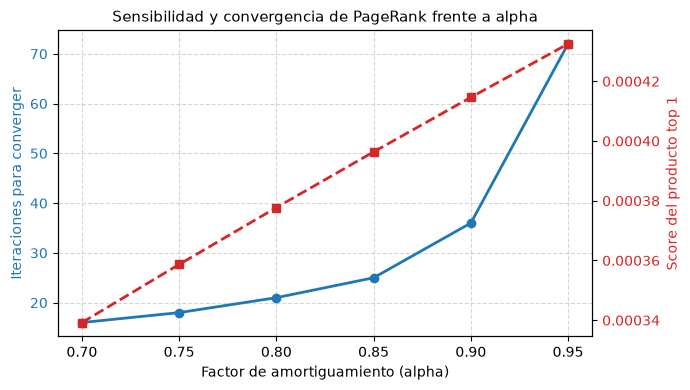

In [10]:
# 6.1 Grilla de alpha en PageRank
tabla_alpha = resultados(R / "grilla_alpha.csv", lambda: benchmark.grilla_alpha(grafo))
display(tabla_alpha[["alpha", "iteraciones", "convergido", "max_score", "std_score", "top1_asin"]])

fig, ax1 = plt.subplots(figsize=(7, 4))
color = "#1f77b4"
ax1.set_xlabel("Factor de amortiguamiento (alpha)", fontsize=10)
ax1.set_ylabel("Iteraciones para converger", color=color, fontsize=10)
ax1.plot(tabla_alpha["alpha"], tabla_alpha["iteraciones"], marker="o", color=color, linewidth=2)
ax1.tick_params(axis="y", labelcolor=color)
ax1.grid(True, linestyle="--", alpha=0.5)

ax2 = ax1.twinx()
color = "#d62728"
ax2.set_ylabel("Score del producto top 1", color=color, fontsize=10)
ax2.plot(tabla_alpha["alpha"], tabla_alpha["top1_score"], marker="s", color=color, linewidth=2, linestyle="--")
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Sensibilidad y convergencia de PageRank frente a alpha", fontsize=11)
fig.tight_layout()
plt.show()

In [11]:
# 6.2 Grilla de resolución de Louvain
tabla_res = resultados(R / "grilla_resolucion.csv", lambda: benchmark.grilla_resolucion(grafo, semilla=SEED))
display(tabla_res)

Resultados leídos de grilla_resolucion.csv


,resolucion,modularidad,n_comunidades,componentes_conexas,comunidades_por_componente,niveles,comunidad_max_nodos,comunidad_mediana_nodos
0,0.5,0.998960,841,841,1.0,3,356,282.0
1,1.0,0.997920,841,841,1.0,3,356,282.0
2,2.0,0.995841,841,841,1.0,3,356,282.0
3,5.0,0.989601,841,841,1.0,3,356,282.0
4,10.0,0.979203,841,841,1.0,3,356,282.0
5,20.0,0.958405,841,841,1.0,3,356,282.0


## Paso 7. Resultados en el pipeline e inspección cualitativa

Vinculamos los índices calculados con el catálogo de la etapa 3 (`AlmacenCatalogo`):
- Los **productos más influyentes** según PageRank, con su grado ponderado.
- Los productos de mayor PageRank dentro de las **comunidades** más grandes de Louvain.

Las comunidades de este grafo no son temáticas. Reproducen los grupos `crc32(asin) % 500` con que el generador de la etapa 0 arma las órdenes con varios productos, así que mezclan categorías sin relación, como cinta adhesiva con impresoras. El paso 10 lo mide con la pureza de categoría frente al azar y valida los algoritmos con el grafo de co-reseñas reales, donde sí hay estructura temática.

In [12]:
# 7.1 Carga del catálogo
almacen = AlmacenCatalogo(RUTA_CATALOGO)

# Top 10 por PageRank
orden_pr = np.argsort(-pr_scores)[:10]
filas_pr = []
for idx in orden_pr:
    asin = grafo.asins[idx]
    reg = almacen.leer(asin) or {}
    precio = reg.get("precio")
    precio_str = f"${float(precio):.2f}" if precio is not None else "N/D"
    filas_pr.append({
        "ASIN": asin,
        "PageRank": f"{pr_scores[idx]:.6f}",
        "Grado_Pond": int(grados_ponderados[idx]),
        "Título": (reg.get("title") or "N/D")[:65],
        "Categoría": reg.get("categoria_hoja") or "N/D",
        "Precio": precio_str
    })

print("--- TOP 10 PRODUCTOS POR PAGERANK (CENTRALIDAD GLOBAL) ---")
display(pd.DataFrame(filas_pr))


--- TOP 10 PRODUCTOS POR PAGERANK (CENTRALIDAD GLOBAL) ---


,ASIN,PageRank,Grado_Pond,Título,Categoría,Precio
0,B0BF98LWMZ,0.000396,1420,TN436 ColorKing Compatible Toner Cartridge Rep...,Toner Cartridges,$62.99
1,B0BN478RWJ,0.000392,1606,HP DeskJet 2755e Wireless Color All-in-One Pri...,Inkjet Printers,$59.99
2,B087S2JRXY,0.000340,1424,"Amazon Basics 15-Sheet Cross-Cut Paper, CD Cre...",Shredders,$131.99
3,B0B3MX7LVG,0.000337,1471,"EZlifego Double Sided Tape Heavy Duty, Extra L...",Mounting Tape,$10.99
4,B0BZ67T58M,0.000330,1391,Office Chair Wheels Replacement Rubber Chair c...,Casters,$39.99
5,B09X5RYD9R,0.000295,751,DIVERSEBEE Bible Highlighters and Pens No Blee...,Highlighters,$9.95
6,B0C36Q7PM4,0.000294,1052,"Amazon Basics Multipurpose Copy Printer Paper,...",Copy & Multipurpose Paper,$8.49
7,B09PWTVGPW,0.000293,1071,"Alientape Nano Double Sided Tape, Multipurpose...",Mounting Tape,$17.95
8,B07GNNGXNK,0.000289,920,"Gorilla Grip Desk Chair Mat, No Divots, Rollin...",Carpet Chair Mats,N/D
9,B082F417S1,0.000252,891,"Leather Desk Pad Protector,Mouse Pad,Office De...",Mouse Pads,$11.89


In [13]:
# 7.2 Productos de mayor PageRank en las cuatro comunidades más grandes de Louvain
top_comunidades = conteo_louvain.head(4).index

for c_id in top_comunidades:
    nodos_c = np.where(comunidades_louvain == c_id)[0]
    # Tomar los de mayor PageRank dentro del clúster
    nodos_c_top = nodos_c[np.argsort(-pr_scores[nodos_c])[:4]]
    print(f"\n=== COMUNIDAD {c_id} (Total miembros: {len(nodos_c):,} productos) ===")
    for idx in nodos_c_top:
        asin = grafo.asins[idx]
        reg = almacen.leer(asin) or {}
        print(f"  [{asin}] ({reg.get('categoria_hoja')}) {(reg.get('title') or '')[:70]}...")

almacen.cerrar()


=== COMUNIDAD 616 (Total miembros: 356 productos) ===
  [B0B3MX7LVG] (Mounting Tape) EZlifego Double Sided Tape Heavy Duty, Extra Large Nano Double Sided A...
  [B09Y8HDMV7] (Desktop Photo Printers) KODAK Dock Plus 4PASS Instant Photo Printer (4x6 inches) + 90 Sheets B...
  [B079PG2BT6] (Laser & Inkjet Printer Labels) Blank White Permanent Adhesive Labels for Laser/Ink Jet Printer (4" x ...
  [B0BVWCML3V] (Ink Tank Printers) Epson EcoTank ET-4850 Wireless All-in-One Cartridge-Free Supertank Pri...

=== COMUNIDAD 251 (Total miembros: 352 productos) ===
  [B07XY35M94] (Pencil Holders) EASTHILL Big Capacity Pencil Pen Case Office College School Large Stor...
  [B0C1KN5CP7] (Lap Desks) HUANUO Adjustable Lap Desk - with 8 Adjustable Angles & Dual Cushions ...
  [B0CBNFP2R5] (Label Printers) Nelko Bluetooth Thermal Shipping Label Printer, Wireless 4x6 for Small...
  [B082Y7DFVC] (Calligraphy Pens) VANGOAL Feather Pen and Ink Set, Glittering Quill Pen Set Antique Call...

=== COMUNIDAD 145 (

## Paso 8. Salidas de la etapa 8

Verificamos la persistencia de los artefactos generados según el contrato de interfaces:
1. `grafo_cocompra.npz`: Matriz dispersa CSR del grafo.
2. `pagerank.parquet`: Puntuaciones de PageRank y Grado Ponderado.
3. `comunidades.parquet`: Asignación de comunidad Louvain y LPA.
4. `metricas.json`: Métricas de convergencia, tiempos y memoria.


In [14]:
for ruta in (RUTA_GRAFO, RUTA_PAGERANK, RUTA_COMUNIDADES, RUTA_METRICAS):
    tam_mb = ruta.stat().st_size / (1024 * 1024)
    print(f"✓ {ruta.name:25s} | Tamaño: {tam_mb:7.2f} MB ({ruta.stat().st_size:,} bytes)")

metricas = json.loads(RUTA_METRICAS.read_text(encoding="utf-8"))
print("\nResumen de Métricas JSON:")
print(json.dumps(metricas, indent=2))


✓ grafo_cocompra.npz        | Tamaño:    5.80 MB (6,081,098 bytes)
✓ pagerank.parquet          | Tamaño:    4.76 MB (4,995,091 bytes)
✓ comunidades.parquet       | Tamaño:    1.82 MB (1,909,904 bytes)
✓ metricas.json             | Tamaño:    0.00 MB (1,379 bytes)

Resumen de Métricas JSON:
{
  "grafo": {
    "nodos": 150534,
    "aristas": 805587,
    "peso_total": 1067474.0,
    "densidad": 7.110106831501846e-05,
    "min_peso": 1,
    "compras_procesadas": 1978936,
    "compras_bloqueadas_excluidas": 31878,
    "ordenes_bloqueadas_excluidas": 31878,
    "ordenes_bloqueadas_con_cocompra": 0,
    "ordenes_legitimas": 1303414,
    "ordenes_con_cocompra": 324550,
    "segundos_extraccion": 69.543312799884,
    "memoria_csr_bytes": 20538368
  },
  "pagerank": {
    "alpha": 0.85,
    "tol": 1e-06,
    "iteraciones": 25,
    "convergido": true,
    "segundos_pagerank": 0.5653392001986504,
    "segundos_grado": 0.0006984998472034931,
    "top1_asin": "B0BF98LWMZ",
    "top1_score": 0.000396

## Paso 9. Experimentos de escalabilidad

### Diseño del experimento

| Experimento | Estructura | Línea base | Complejidad esperada |
| --- | --- | --- | --- |
| 9.1 Influencia | PageRank con SpMV sobre el CSR | Grado ponderado | $O(k \cdot (\|V\| + \|E\|))$ frente a $O(\|V\| + \|E\|)$ |
| 9.2 Comunidades | Louvain multinivel | LPA | ≈ $O(\|E\|)$ por pasada en los dos |
| 9.3 Referencia | PageRank y Louvain propios | NetworkX 3.7 | Las mismas complejidades; se compara la implementación |
| 9.4 Escala medida | La etapa completa sobre el stream regenerado | — | Lineal en el número de eventos y de aristas |

**Datos.** Para 9.1 a 9.3 se forman subgrafos de 1 000, 10 000, 50 000 y 100 000 nodos uniendo componentes conexas completas elegidas con la semilla, más el grafo completo de 150 534 nodos. Unir componentes enteras conserva el grado medio del grafo en cada tamaño (auditoría 2026-10-27). NetworkX se mide en los subgrafos de hasta 50 000 nodos (`N_MAX_NETWORKX`), porque guarda un diccionario por nodo y por arista; como los subgrafos unen componentes completas, el de 50 000 queda en 50 127 nodos, fuera del límite, y la comparación cubre los de 1 235 y 10 222 nodos. El experimento 9.4 regenera el stream de la etapa 0 con ventanas crecientes de reseñas reales, de 150 000 a las 12 845 712 del dataset, y corre la etapa entera en un subproceso por tamaño; cubre de 1 M a 92 M eventos. Ahí el filtro de fraude usa la verdad de referencia del generador, porque el detector de la etapa 6 no se recorre a esa escala.

**Repeticiones.** La primera ejecución de cada medición fija cuántas repeticiones caben en `PRESUPUESTO_S` = 120 s, el mismo presupuesto de 2 minutos por medición que las etapas 5 y 7, con un máximo de 100 y un mínimo de 1. Cada tabla guarda el promedio, la desviación estándar, las repeticiones y la primera medición. El experimento 9.4 se hace una vez por tamaño, porque el tamaño mayor tarda varios minutos y su objetivo es comprobar que la etapa completa escala, no comparar estructuras.

**Condiciones de medición.**

- **Reloj.** `time.perf_counter`, con el recolector de basura desactivado durante cada medición.
- **Memoria.** `tracemalloc`, en una pasada aparte sin medir tiempo, porque el rastreo hace más lenta cada asignación. La versión anterior de este paso medía el tiempo con el rastreo activo: en la plataforma de esa medición, Louvain tardaba 88 s en el grafo completo con el rastreo y unos 4 s sin él (revisión técnica, punto 1.4). En 9.4 la memoria es la residente máxima de cada subproceso.
- **Plataforma y semilla.** Cada tabla guarda su procesador y su versión de Python, y cada figura lo indica. La semilla es la del paso 1.

In [15]:
# 9.1 a 9.3: subgrafos, PageRank, comunidades y NetworkX
subgrafos = benchmark.generar_subgrafos_muestra(grafo, tamanos=benchmark.TAMANOS, semilla=SEED)
escala_pr = resultados(R / "escala_pagerank.csv", lambda: benchmark.escala_pagerank(subgrafos),
                       requeridas=["ms_pagerank_std", "ms_pagerank_primera"])
escala_com = resultados(R / "escala_comunidades.csv", lambda: benchmark.escala_comunidades(subgrafos, semilla=SEED),
                        requeridas=["segundos_louvain_std", "segundos_lpa_primera"])
ref_nx = resultados(R / "referencia_networkx.csv",
                    lambda: benchmark.referencia_networkx(subgrafos, escala_pr, escala_com, semilla=SEED),
                    requeridas=["ms_pagerank_nx_std", "error_max_pagerank"])

print("--- ESCALA PAGERANK ---")
display(escala_pr)

print("--- ESCALA COMUNIDADES (LOUVAIN Y LPA) ---")
display(escala_com)

print("--- COMPARACIÓN CON NETWORKX ---")
display(ref_nx)

Subgrafo 1,000: 1,235 nodos, 7,059 aristas


Subgrafo 10,000: 10,222 nodos, 55,884 aristas


Subgrafo 50,000: 50,127 nodos, 269,450 aristas


Subgrafo 100,000: 100,225 nodos, 537,698 aristas
escala_pagerank.csv es de una versión anterior del experimento y se mide de nuevo


PageRank n = 1,235: 2.6 ms (100 repeticiones)


PageRank n = 10,222: 30.0 ms (100 repeticiones)


... (14 outputs left out)

--- ESCALA COMUNIDADES (LOUVAIN Y LPA) ---


,n,aristas,segundos_louvain,segundos_louvain_std,segundos_louvain_repeticiones,segundos_louvain_primera,modularidad_louvain,comunidades_louvain,niveles_louvain,mem_actual_louvain_bytes,...,segundos_lpa_std,segundos_lpa_repeticiones,segundos_lpa_primera,modularidad_lpa,comunidades_lpa,iteraciones_lpa,mem_actual_lpa_bytes,mem_pico_lpa_bytes,procesador,python
0,1235,7059,0.066093,0.001721,100,0.067085,0.743634,6,3,16771,...,0.002510,100,0.043995,0.742137,19,5,10725,460832,"AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD",3.12.0
1,10222,55884,0.812212,0.030248,100,0.809537,0.969223,48,3,52617,...,0.017778,100,0.516702,0.967720,100,7,47561,3410453,"AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD",3.12.0
2,50127,269450,3.521944,0.067645,35,3.420415,0.993733,276,4,213251,...,0.047232,55,2.174953,0.991620,577,6,207122,16432748,"AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD",3.12.0
3,100225,537698,11.831925,0.085104,10,11.826191,0.996867,562,3,414419,...,0.074101,21,5.649591,0.994741,1156,8,407794,32789176,"AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD",3.12.0
4,150534,805587,14.314519,0.030104,8,14.377859,0.997920,841,3,615991,...,0.074911,10,11.219423,0.995856,1712,11,609878,49133967,"AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD",3.12.0


--- COMPARACIÓN CON NETWORKX ---


,n,aristas,ms_pagerank_propio,segundos_louvain_propio,ms_pagerank_nx,ms_pagerank_nx_std,ms_pagerank_nx_repeticiones,ms_pagerank_nx_primera,segundos_louvain_nx,segundos_louvain_nx_std,...,segundos_louvain_nx_primera,speedup_pagerank,speedup_louvain,error_max_pagerank,modularidad_propia,modularidad_nx,comunidades_propia,comunidades_nx,procesador,python
0,1235,7059,2.572675,0.066093,10.029106,3.012025,100,39.4653,0.084349,0.002755,...,0.083954,3.898318,1.276201,0.000058,0.743634,0.743634,6,6,"AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD",3.12.0
1,10222,55884,30.008782,0.812212,75.749566,2.082315,100,81.8705,0.900827,0.010784,...,0.871569,2.524247,1.109103,0.000017,0.969223,0.969223,48,48,"AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD",3.12.0


In [16]:
# 9.4 Escala medida: la etapa completa sobre el stream regenerado, un subproceso por tamaño
escala_st = resultados(R / "escala_stream.csv", lambda: escala_stream.medir_tamanos(escala_stream.TAMANOS),
                       requeridas=["asins_vacios_descartados"])
display(escala_st[["resenas", "eventos", "compras", "compras_fraude_excluidas", "asins_vacios_descartados", "nodos",
                   "aristas", "componentes", "componente_max", "comunidades_louvain", "louvain_igual_componentes",
                   "segundos_pagerank", "segundos_louvain", "segundos_lpa", "rss_pico_gb", "segundos_total"]])

escala_stream.csv es de una versión anterior del experimento y se mide de nuevo
--- 150,000 reseñas ---


{"resenas": 150000, "eventos": 1079556, "compras": 221912, "compras_fraude_excluidas": 3658, "asins_vacios_descartados": 356, "segundos_stream": 13.063298200024292, "nodos": 39279, "aristas": 102347, "peso_total": 114583.0, "memoria_csr_mb": 2.6422195434570312, "segundos_grafo": 0.7356742999982089, "segundos_pagerank": 0.1016869000159204, "iteraciones_pagerank": 43, "segundos_componentes": 0.007077299989759922, "componentes": 1003, "componente_max": 103, "segundos_louvain": 3.5499227000400424, "modularidad_louvain": 0.9978951035462732, "comunidades_louvain": 1003, "louvain_desconectadas": 0, "louvain_igual_componentes": true, "modularidad_componentes": 0.9978951035462732, "segundos_lpa": 2.47046949993819, "modularidad_lpa": 0.8661320782064144, "comunidades_lpa": 2969, "lpa_desconectadas": 9, "rss_pico_gb": 0.6771621704101562, "segundos_total": 20.07989910012111}


--- 375,000 reseñas ---


{"resenas": 375000, "eventos": 2631729, "compras": 522825, "compras_fraude_excluidas": 9285, "asins_vacios_descartados": 816, "segundos_stream": 27.074760999996215, "nodos": 68489, "aristas": 232089, "peso_total": 271574.0, "memoria_csr_mb": 5.834632873535156, "segundos_grafo": 1.5364845001604408, "segundos_pagerank": 0.22398229991085827, "iteraciones_pagerank": 38, "segundos_componentes": 0.020838500000536442, "componentes": 931, "componente_max": 167, "segundos_louvain": 7.5581451000180095, "modularidad_louvain": 0.997911786657219, "comunidades_louvain": 931, "louvain_desconectadas": 0, "louvain_igual_componentes": true, "modularidad_componentes": 0.9979117866572189, "segundos_lpa": 5.458652199944481, "modularidad_lpa": 0.9557664974928918, "comunidades_lpa": 2384, "lpa_desconectadas": 18, "rss_pico_gb": 0.6521644592285156, "segundos_total": 42.03045280021615}


--- 750,000 reseñas ---


{"resenas": 750000, "eventos": 5227798, "compras": 1029495, "compras_fraude_excluidas": 20084, "asins_vacios_descartados": 1616, "segundos_stream": 54.01806849986315, "nodos": 101747, "aristas": 433388, "peso_total": 534321.0, "memoria_csr_mb": 10.69573974609375, "segundos_grafo": 2.6999215001706034, "segundos_pagerank": 0.33000519988127053, "iteraciones_pagerank": 33, "segundos_componentes": 0.04022460011765361, "componentes": 865, "componente_max": 252, "segundos_louvain": 11.296428699977696, "modularidad_louvain": 0.9979184838947273, "comunidades_louvain": 865, "louvain_desconectadas": 0, "louvain_igual_componentes": true, "modularidad_componentes": 0.9979184838947273, "segundos_lpa": 6.744612099835649, "modularidad_lpa": 0.987322751021158, "comunidades_lpa": 1938, "lpa_desconectadas": 11, "rss_pico_gb": 0.8239936828613281, "segundos_total": 75.35045309993438}


... (6 outputs left out)

--- 12,845,712 reseñas ---


{"resenas": 12845712, "eventos": 92418622, "compras": 19108958, "compras_fraude_excluidas": 335487, "asins_vacios_descartados": 30321, "segundos_stream": 935.2578559000976, "nodos": 583603, "aristas": 5382454, "peso_total": 9932632.0, "memoria_csr_mb": 127.64714050292969, "segundos_grafo": 34.69879280007444, "segundos_pagerank": 4.058532899944112, "iteraciones_pagerank": 24, "segundos_componentes": 0.8759433999657631, "componentes": 899, "componente_max": 1312, "segundos_louvain": 107.16342529980466, "modularidad_louvain": 0.997934343372666, "comunidades_louvain": 899, "louvain_desconectadas": 0, "louvain_igual_componentes": true, "modularidad_componentes": 0.997934343372666, "segundos_lpa": 116.60019310005009, "modularidad_lpa": 0.975038307138949, "comunidades_lpa": 2096, "lpa_desconectadas": 10, "rss_pico_gb": 6.5550689697265625, "segundos_total": 1200.6361910998821}


Resultados guardados en escala_stream.csv


,resenas,eventos,compras,compras_fraude_excluidas,asins_vacios_descartados,nodos,aristas,componentes,componente_max,comunidades_louvain,louvain_igual_componentes,segundos_pagerank,segundos_louvain,segundos_lpa,rss_pico_gb,segundos_total
0,150000,1079556,221912,3658,356,39279,102347,1003,103,1003,True,0.101687,3.549923,2.470469,0.677162,20.079899
1,375000,2631729,522825,9285,816,68489,232089,931,167,931,True,0.223982,7.558145,5.458652,0.652164,42.030453
2,750000,5227798,1029495,20084,1616,101747,433388,865,252,865,True,0.330005,11.296429,6.744612,0.823994,75.350453
3,1500000,10512167,2085024,38576,3337,151026,815051,836,356,836,True,0.545555,15.605043,10.551023,1.189880,139.806407
4,3000000,21422752,4366036,79024,6896,233655,1563682,797,538,797,True,0.948163,22.990315,11.995910,1.930416,266.619973
5,6000000,43287024,8965206,158596,14445,342310,2802528,767,776,767,True,1.372526,31.909779,28.604487,3.493343,527.913371
6,12845712,92418622,19108958,335487,30321,583603,5382454,899,1312,899,True,4.058533,107.163425,116.600193,6.555069,1200.636191


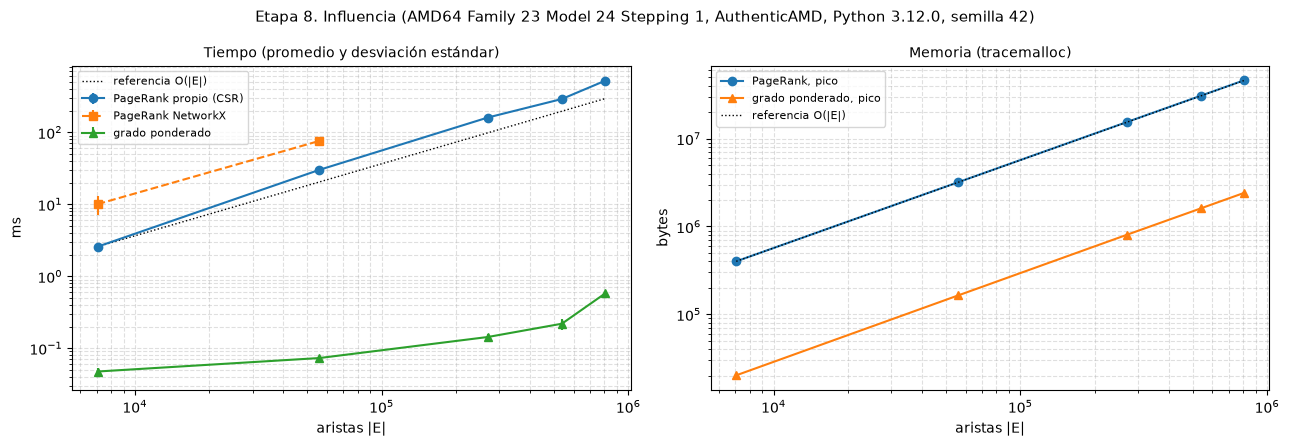

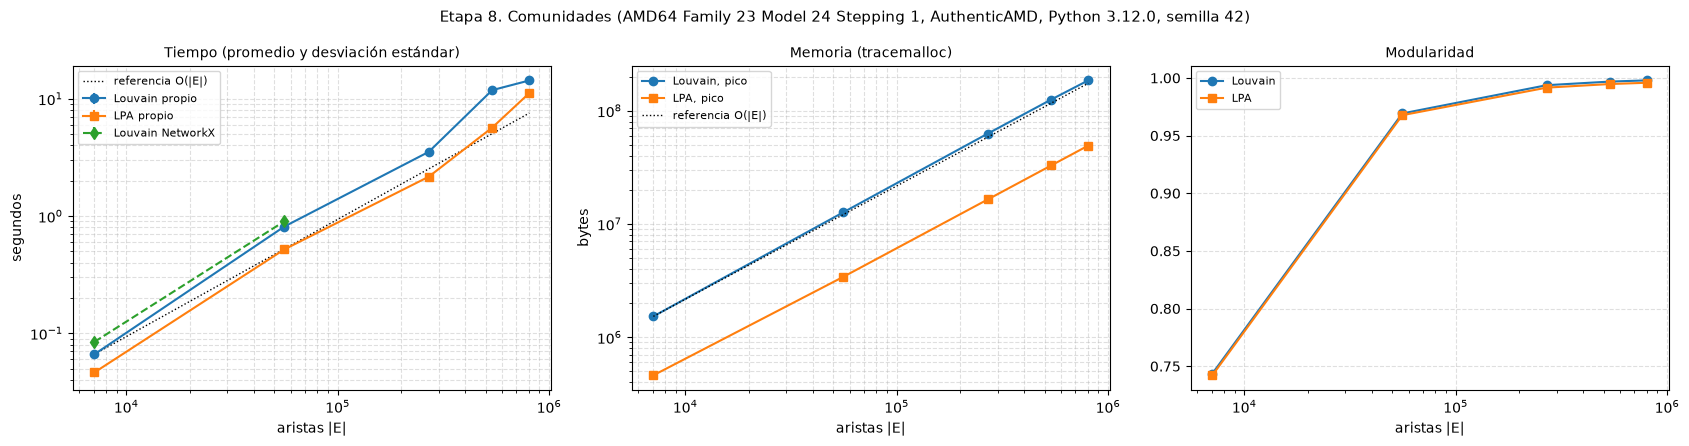

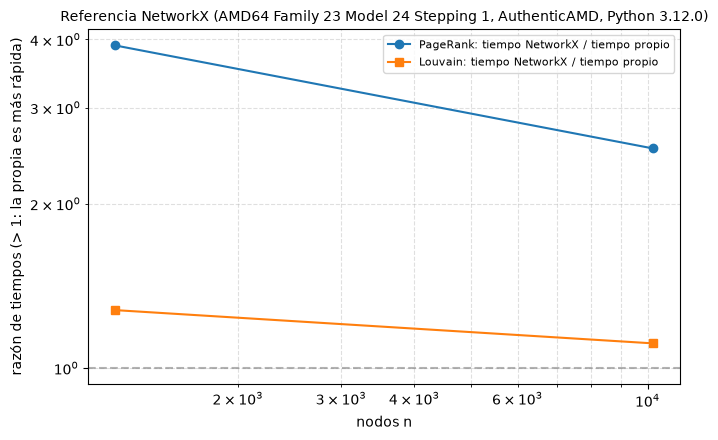

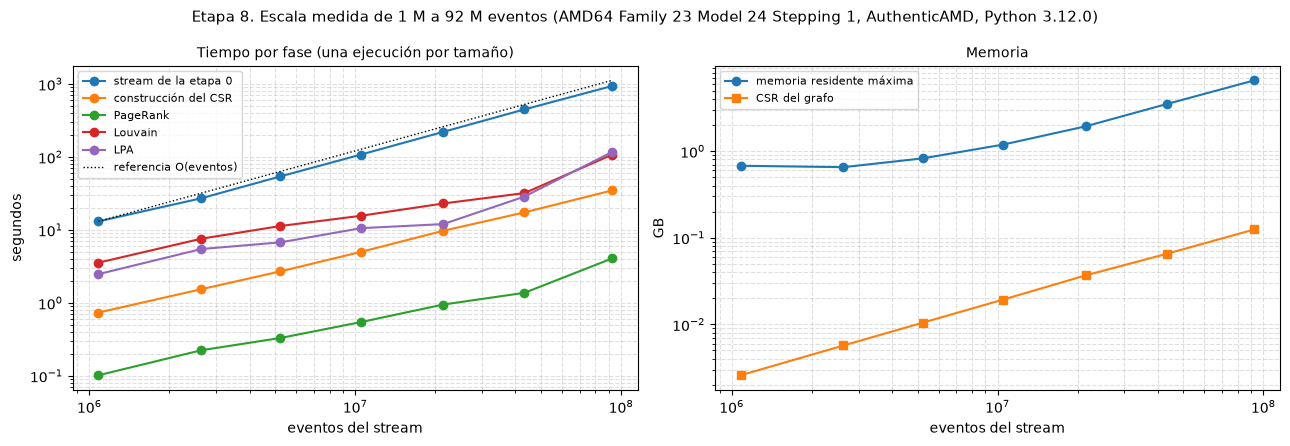

In [17]:
# 9.5 Gráficas log-log con rectas de referencia
def ejes_loglog(ax, titulo, ylabel, xlabel="aristas |E|"):
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(titulo, fontsize=10); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.grid(True, which="both", linestyle="--", alpha=0.4)
    ax.legend(fontsize=8)


def referencia(ax, x, y, etiqueta="referencia O(|E|)"):
    """Recta de pendiente 1 que pasa por el primer punto medido."""
    ax.plot(x, y.iloc[0] * x / x.iloc[0], "k:", lw=1, label=etiqueta)


# Influencia: tiempo y memoria
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].errorbar(escala_pr["aristas"], escala_pr["ms_pagerank"], yerr=escala_pr["ms_pagerank_std"], fmt="o-",
                 label="PageRank propio (CSR)")
axes[0].errorbar(ref_nx["aristas"], ref_nx["ms_pagerank_nx"], yerr=ref_nx["ms_pagerank_nx_std"], fmt="s--",
                 label="PageRank NetworkX")
axes[0].errorbar(escala_pr["aristas"], escala_pr["ms_grado"], yerr=escala_pr["ms_grado_std"], fmt="^-",
                 label="grado ponderado")
referencia(axes[0], escala_pr["aristas"], escala_pr["ms_pagerank"])
ejes_loglog(axes[0], "Tiempo (promedio y desviación estándar)", "ms")
axes[1].plot(escala_pr["aristas"], escala_pr["mem_pico_pr_bytes"], "o-", label="PageRank, pico")
axes[1].plot(escala_pr["aristas"], escala_pr["mem_pico_grado_bytes"], "^-", label="grado ponderado, pico")
referencia(axes[1], escala_pr["aristas"], escala_pr["mem_pico_pr_bytes"])
ejes_loglog(axes[1], "Memoria (tracemalloc)", "bytes")
fig.suptitle(f"Etapa 8. Influencia ({plataforma_de(escala_pr)}, semilla {SEED})", fontsize=11)
fig.tight_layout(); fig.savefig(R / "escala_pagerank.png", dpi=150); plt.show()

# Comunidades: tiempo, memoria y modularidad
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].errorbar(escala_com["aristas"], escala_com["segundos_louvain"], yerr=escala_com["segundos_louvain_std"],
                 fmt="o-", label="Louvain propio")
axes[0].errorbar(escala_com["aristas"], escala_com["segundos_lpa"], yerr=escala_com["segundos_lpa_std"],
                 fmt="s-", label="LPA propio")
axes[0].errorbar(ref_nx["aristas"], ref_nx["segundos_louvain_nx"], yerr=ref_nx["segundos_louvain_nx_std"],
                 fmt="d--", label="Louvain NetworkX")
referencia(axes[0], escala_com["aristas"], escala_com["segundos_louvain"])
ejes_loglog(axes[0], "Tiempo (promedio y desviación estándar)", "segundos")
axes[1].plot(escala_com["aristas"], escala_com["mem_pico_louvain_bytes"], "o-", label="Louvain, pico")
axes[1].plot(escala_com["aristas"], escala_com["mem_pico_lpa_bytes"], "s-", label="LPA, pico")
referencia(axes[1], escala_com["aristas"], escala_com["mem_pico_louvain_bytes"])
ejes_loglog(axes[1], "Memoria (tracemalloc)", "bytes")
axes[2].plot(escala_com["aristas"], escala_com["modularidad_louvain"], "o-", label="Louvain")
axes[2].plot(escala_com["aristas"], escala_com["modularidad_lpa"], "s-", label="LPA")
axes[2].set_xscale("log"); axes[2].set_title("Modularidad", fontsize=10); axes[2].set_xlabel("aristas |E|")
axes[2].grid(True, linestyle="--", alpha=0.4); axes[2].legend(fontsize=8)
fig.suptitle(f"Etapa 8. Comunidades ({plataforma_de(escala_com)}, semilla {SEED})", fontsize=11)
fig.tight_layout(); fig.savefig(R / "escala_comunidades.png", dpi=150); plt.show()

# Implementaciones propias frente a NetworkX
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ref_nx["n"], ref_nx["speedup_pagerank"], "o-", label="PageRank: tiempo NetworkX / tiempo propio")
ax.plot(ref_nx["n"], ref_nx["speedup_louvain"], "s-", label="Louvain: tiempo NetworkX / tiempo propio")
ax.axhline(1.0, color="gray", linestyle="--", alpha=0.6)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("nodos n"); ax.set_ylabel("razón de tiempos (> 1: la propia es más rápida)")
ax.set_title(f"Referencia NetworkX ({plataforma_de(ref_nx)})", fontsize=10)
ax.grid(True, which="both", linestyle="--", alpha=0.4); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(R / "referencia_networkx.png", dpi=150); plt.show()

# Escala medida sobre el stream regenerado
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for columna, etiqueta in (("segundos_stream", "stream de la etapa 0"), ("segundos_grafo", "construcción del CSR"),
                          ("segundos_pagerank", "PageRank"), ("segundos_louvain", "Louvain"), ("segundos_lpa", "LPA")):
    axes[0].plot(escala_st["eventos"], escala_st[columna], "o-", label=etiqueta)
referencia(axes[0], escala_st["eventos"], escala_st["segundos_stream"], "referencia O(eventos)")
ejes_loglog(axes[0], "Tiempo por fase (una ejecución por tamaño)", "segundos", "eventos del stream")
axes[1].plot(escala_st["eventos"], escala_st["rss_pico_gb"], "o-", label="memoria residente máxima")
axes[1].plot(escala_st["eventos"], escala_st["memoria_csr_mb"] / 1024, "s-", label="CSR del grafo")
ejes_loglog(axes[1], "Memoria", "GB", "eventos del stream")
fig.suptitle(f"Etapa 8. Escala medida de 1 M a 92 M eventos ({plataforma_de(escala_st)})", fontsize=11)
fig.tight_layout(); fig.savefig(R / "escala_stream.png", dpi=150); plt.show()

In [18]:
# 9.6 Pendientes log-log y extrapolación a 10 M nodos
# Ajuste log-log: log(T) = a * log(n) + b  =>  T = 10^b * n^a
def extrapolar(x, y, objetivo=10_000_000):
    """(pendiente log-log de y frente a x, valor extrapolado a `objetivo`)."""
    p = np.polyfit(np.log10(x), np.log10(y), deg=1)
    return p[0], 10 ** (p[1] + p[0] * np.log10(objetivo))


filas = []
for medida, tabla, columna, a_segundos in [
        ("PageRank, subgrafos (9.1)", escala_pr, "ms_pagerank", 1e-3),
        ("Louvain, subgrafos (9.2)", escala_com, "segundos_louvain", 1.0),
        ("LPA, subgrafos (9.2)", escala_com, "segundos_lpa", 1.0),
        ("PageRank, stream (9.4)", escala_st, "segundos_pagerank", 1.0),
        ("Louvain, stream (9.4)", escala_st, "segundos_louvain", 1.0),
        ("LPA, stream (9.4)", escala_st, "segundos_lpa", 1.0)]:
    nodos = tabla["n"] if "n" in tabla.columns else tabla["nodos"]
    pendiente, valor = extrapolar(nodos, tabla[columna] * a_segundos)
    filas.append({"medida": medida, "nodos_medidos": f"{nodos.min():,} a {nodos.max():,}",
                  "pendiente_log_log": round(pendiente, 2), "segundos_extrapolados_a_10M_nodos": round(valor, 1)})
display(pd.DataFrame(filas))

,medida,nodos_medidos,pendiente_log_log,segundos_extrapolados_a_10M_nodos
0,"PageRank, subgrafos (9.1)","1,235 a 150,534",1.09,48.6
1,"Louvain, subgrafos (9.2)","1,235 a 150,534",1.13,1727.5
2,"LPA, subgrafos (9.2)","1,235 a 150,534",1.11,958.8
3,"PageRank, stream (9.4)","39,279 a 583,603",1.30,133.3
4,"Louvain, stream (9.4)","39,279 a 583,603",1.15,2016.1
5,"LPA, stream (9.4)","39,279 a 583,603",1.28,2565.5


In [19]:
# 9.7 Verificación del protocolo de repeticiones
for experimento, tabla, columnas in [("9.1", escala_pr, ["ms_pagerank", "ms_grado"]),
                                     ("9.2", escala_com, ["segundos_louvain", "segundos_lpa"]),
                                     ("9.3", ref_nx, ["ms_pagerank_nx", "segundos_louvain_nx"])]:
    for columna in columnas:
        primera_s = tabla[f"{columna}_primera"] / (1e3 if columna.startswith("ms_") else 1.0)
        esperadas = primera_s.map(benchmark.repeticiones_que_caben)
        assert (tabla[f"{columna}_repeticiones"] == esperadas).all(), f"{experimento}: {columna}"
        for i in tabla.index[tabla[f"{columna}_repeticiones"] < benchmark.REPETICIONES]:
            print(f"{experimento}, {columna}, n = {int(tabla.at[i, 'n']):,}: "
                  f"{int(tabla.at[i, f'{columna}_repeticiones'])} repeticiones de {primera_s[i]:.1f} s; "
                  f"100 tardarían {100 * primera_s[i] / 60:.0f} min")
print(f"Cada tiempo tiene las repeticiones que caben en {benchmark.PRESUPUESTO_S} s, "
      f"con un máximo de {benchmark.REPETICIONES}.")

9.2, segundos_louvain, n = 50,127: 35 repeticiones de 3.4 s; 100 tardarían 6 min
9.2, segundos_louvain, n = 100,225: 10 repeticiones de 11.8 s; 100 tardarían 20 min
9.2, segundos_louvain, n = 150,534: 8 repeticiones de 14.4 s; 100 tardarían 24 min
9.2, segundos_lpa, n = 50,127: 55 repeticiones de 2.2 s; 100 tardarían 4 min
9.2, segundos_lpa, n = 100,225: 21 repeticiones de 5.6 s; 100 tardarían 9 min
9.2, segundos_lpa, n = 150,534: 10 repeticiones de 11.2 s; 100 tardarían 19 min
Cada tiempo tiene las repeticiones que caben en 120 s, con un máximo de 100.


### Lectura de los resultados

- **9.1, influencia.** PageRank crece con pendiente log-log 1.09 frente a los nodos (1.10 frente a las aristas), lo esperado para $O(k \cdot (|V| + |E|))$ con un número de iteraciones $k$ casi constante. En el grafo completo tarda 520.0 ± 5.9 ms (100 repeticiones, 25 iteraciones) y su memoria pico es de 44 MB, unos 57 bytes por arista. El grado ponderado tarda 0.58 ± 0.04 ms; su pendiente de 0.45 indica que en estos tamaños domina el costo fijo de la llamada y no el recorrido del CSR.
- **9.2, comunidades.** Sin el rastreo de memoria, Louvain tiene pendiente 1.13 y LPA 1.11 frente a los nodos, cerca de lineal. En el grafo completo Louvain tarda 14.31 ± 0.03 s (8 repeticiones) y LPA 11.17 ± 0.07 s (10 repeticiones); desde 50 000 nodos caben de 8 a 55 repeticiones en los 120 s del presupuesto (9.7). La memoria pico de Louvain es de 176 MB, unos 230 bytes por arista y 9 veces el CSR (19.6 MB), por los diccionarios de adyacencia de cada nivel; la de LPA es de 47 MB, unos 61 bytes por arista. Las dos llegan a modularidades casi iguales (0.9979 y 0.9959) porque el grafo es una unión de componentes densas.
- **9.3, NetworkX.** PageRank propio es 3.9 veces más rápido que el de NetworkX con 1 235 nodos y 2.5 veces con 10 222; Louvain propio, 1.28 y 1.11 veces. Louvain da la misma modularidad y el mismo número de comunidades que NetworkX en los dos tamaños (0.7436 con 6 comunidades y 0.9692 con 48). El error máximo de PageRank es de 5.8 × 10⁻⁵ y 1.7 × 10⁻⁵: NetworkX se detiene cuando la diferencia L1 entre iteraciones baja de $N \cdot tol$, un criterio más laxo que el de la implementación propia ($10^{-6}$ en L1).
- **9.4, escala medida.** El filtro descarta las compras con ASIN vacío: de 356 a 30 321 según el tamaño. La versión anterior las contaba como un nodo `""` que unía 582 838 de los 583 653 nodos en una sola componente; ahora el grafo de las 12.8 M reseñas tiene 583 603 nodos, 5.4 M aristas y 899 componentes, la mayor de 1 312 nodos, y Louvain devuelve exactamente las componentes en todos los tamaños. El stream es lineal en los eventos (pendiente 0.97) y la construcción del CSR, lineal en las aristas (0.97). PageRank, Louvain y LPA tienen pendientes de 0.87, 0.76 y 0.85 frente a las aristas, por debajo de 1 porque los tamaños pequeños cargan costos fijos. La etapa completa con 92.4 M eventos tarda 20 min, 16 de ellos en el stream, con una memoria residente máxima de 6.6 GB.
- **Extrapolación.** Con las pendientes frente a los nodos de 9.6, a 10 M nodos PageRank tardaría de 49 a 133 s, Louvain de 29 a 34 min y LPA de 16 a 43 min, según se extrapole desde los subgrafos o desde el stream. La proyección desde el stream es mayor porque ahí las aristas crecen más rápido que los nodos (el grado medio pasa de 5.2 a 18.4). La versión anterior proyectaba 3 h de Louvain con tiempos medidos con `tracemalloc` activo.

## Paso 10. Auditoría técnica, validación con datos reales y estabilidad

Verificaciones añadidas tras la auditoría de las etapas 8 y 9 (2026-10-27) y la revisión técnica del proyecto (2026-10-28):
1. **Conexión de comunidades (Louvain vs Leiden).** Se cuentan las comunidades internamente desconectadas y se parten en sus componentes con `dividir_comunidades_desconectadas`, en $O(|V| + |E|)$ y sin bajar $Q$.
2. **Comunidades frente a componentes conexas.** Si la partición coincide con las componentes, Louvain no aporta estructura más allá de un BFS.
3. **Pureza temática.** Fracción de productos cuya `categoria_hoja` es la mayoritaria de su comunidad, frente a la misma partición con etiquetas permutadas al azar.
4. **PageRank frente al grado.** En un grafo no dirigido el estado estacionario sin teletransporte es $k_i / 2m$; se mide cuánto se separa PageRank del grado.
5. **Validación con co-reseñas reales.** Los mismos algoritmos sobre un grafo construido con las reseñas reales del dataset (10.4).
6. **Estabilidad.** Louvain y LPA con varias semillas, comparados con NMI y ARI (10.5).

In [20]:
# 10.1 Conexión de comunidades y contraste con componentes conexas
from scipy.stats import spearmanr

grafo_a = GrafoCoCompra.cargar_npz(RUTA_GRAFO)
com_a = pd.read_parquet(RUTA_COMUNIDADES)
n_cc, etiquetas_cc = componentes_conexas(grafo_a)
filas_aud = []
for col in ("comunidad_louvain", "comunidad_lpa"):
    particion = com_a[col].to_numpy()
    _, n_desconectadas = dividir_comunidades_desconectadas(grafo_a, particion)
    pares = np.unique(np.stack([particion, etiquetas_cc], axis=1), axis=0)
    filas_aud.append({
        "particion": col,
        "comunidades": len(np.unique(particion)),
        "componentes_conexas": n_cc,
        "comunidades_desconectadas": n_desconectadas,
        "igual_a_componentes": len(pares) == n_cc == len(np.unique(particion)),
        "modularidad": modularidad(grafo_a, particion),
    })
display(pd.DataFrame(filas_aud))
print(f"Q de la partición por componentes conexas: {modularidad(grafo_a, etiquetas_cc):.6f}")

,particion,comunidades,componentes_conexas,comunidades_desconectadas,igual_a_componentes,modularidad
0,comunidad_louvain,841,841,0,True,0.997920
1,comunidad_lpa,1712,841,0,False,0.995856


Q de la partición por componentes conexas: 0.997920


In [21]:
# 10.2 Pureza temática de las comunidades frente al azar
categoria_por_asin = {}
with open(RUTA_CATALOGO, encoding="utf-8") as f:
    for linea in f:
        prod = json.loads(linea)
        categoria_por_asin[prod["parent_asin"]] = prod.get("categoria_hoja")
com_a["categoria"] = com_a["parent_asin"].map(categoria_por_asin)


def pureza(df, col):
    g = df.dropna(subset=["categoria"]).groupby(col)["categoria"]
    return g.agg(lambda s: s.value_counts().iloc[0]).sum() / g.size().sum()


rng_a = np.random.default_rng(SEED)
permutada = com_a.assign(comunidad_louvain=rng_a.permutation(com_a["comunidad_louvain"].to_numpy()))
print(f"Pureza Louvain:            {pureza(com_a, 'comunidad_louvain'):.4f}")
print(f"Pureza con etiquetas azar: {pureza(permutada, 'comunidad_louvain'):.4f}")

# 10.3 PageRank frente al grado ponderado
pr_a = pd.read_parquet(RUTA_PAGERANK)
rho = spearmanr(pr_a["pagerank_score"], pr_a["grado_ponderado"]).correlation
top_pr = set(pr_a.nlargest(100, "pagerank_score")["parent_asin"])
top_gr = set(pr_a.nlargest(100, "grado_ponderado")["parent_asin"])
print(f"Spearman(PageRank, grado ponderado) = {rho:.4f}; coincidencia Top-100 = {len(top_pr & top_gr)}")

Pureza Louvain:            0.0672


Pureza con etiquetas azar: 0.0674
Spearman(PageRank, grado ponderado) = 0.9565; coincidencia Top-100 = 84


### 10.4 Validación con el grafo de co-reseñas reales

Las co-compras del stream son sintéticas, así que los resultados de los pasos 4 a 7 describen al generador. La única señal de comportamiento real del dataset son las reseñas. `grafo_resenas_reales.py` aplica los mismos algoritmos a un grafo de **co-reseñas**: una arista $u$–$v$ con peso $w$ indica que $w$ usuarios reseñaron $v$ inmediatamente después de $u$, sobre las 12 845 712 reseñas del dataset. Ese grafo no pasa por el filtro de fraude de la etapa 6 ni cumple la definición del enunciado (productos de la misma orden), así que la etapa 9 sigue usando el de co-compra (`FUENTE_COCOMPRA` en `src/etapa_9/service.py`); aquí sirve para comprobar que los algoritmos encuentran estructura cuando la hay. La grilla de resolución muestra el efecto del límite de resolución sobre la pureza temática.

In [22]:
# 10.4 Validación con el grafo de co-reseñas reales
resultados_archivos([resenas.RUTA_SALIDA, resenas.RUTA_GRAFO_RESENAS], resenas.main)
validacion = json.loads(resenas.RUTA_SALIDA.read_text(encoding="utf-8"))
grilla_resenas = resultados(R / "grilla_resolucion_resenas.csv", resenas.grilla_resolucion)

comparacion = pd.DataFrame({
    "co-compra (generador)": {
        "nodos": grafo_a.n_nodos, "aristas": grafo_a.n_aristas, "componentes": n_cc,
        "modularidad Louvain": modularidad(grafo_a, com_a["comunidad_louvain"].to_numpy()),
        "modularidad LPA": modularidad(grafo_a, com_a["comunidad_lpa"].to_numpy()),
        "comunidades Louvain": com_a["comunidad_louvain"].nunique(),
        "pureza de categoría Louvain": pureza(com_a, "comunidad_louvain"),
        "pureza de categoría al azar": pureza(permutada, "comunidad_louvain"),
        "Spearman PageRank-grado": rho,
    },
    "co-reseñas (reales)": {
        "nodos": validacion["nodos"], "aristas": validacion["aristas"], "componentes": validacion["componentes"],
        "modularidad Louvain": validacion["modularidad_louvain"], "modularidad LPA": validacion["modularidad_lpa"],
        "comunidades Louvain": validacion["comunidades_louvain"],
        "pureza de categoría Louvain": validacion["pureza_categoria_louvain"],
        "pureza de categoría al azar": validacion["pureza_categoria_azar"],
        "Spearman PageRank-grado": validacion["spearman_pr_grado"],
    },
})
display(comparacion)
display(grilla_resenas)

Resultados leídos de grafo_resenas_reales.json, grafo_resenas.npz
Resultados leídos de grilla_resolucion_resenas.csv


,co-compra (generador),co-reseñas (reales)
nodos,150534.000000,5.795470e+05
aristas,805587.000000,4.733125e+06
componentes,841.000000,3.408000e+03
modularidad Louvain,0.997920,3.222156e-01
modularidad LPA,0.995856,7.696150e-03
comunidades Louvain,841.000000,4.272000e+03
pureza de categoría Louvain,0.067226,1.055396e-01
pureza de categoría al azar,0.067411,5.869654e-02
Spearman PageRank-grado,0.956458,8.954609e-01


,resolucion,modularidad_gamma,modularidad_gamma1,comunidades,comunidades_10_o_mas,mayor_comunidad,segundos,pureza_categoria,pureza_categoria_azar,pureza_tienda,pureza_tienda_azar
0,1.0,0.322216,0.322216,4272,81,139900,75.577196,0.105540,0.058697,0.027878,0.014413
1,2.0,0.255925,0.280697,3558,137,25921,115.505186,0.145506,0.057733,0.036313,0.013510
2,5.0,0.219629,0.245686,3966,541,15219,136.788537,0.157819,0.059528,0.047997,0.015030
3,10.0,0.197208,0.227377,4641,1210,11223,209.792022,0.160367,0.062185,0.054542,0.017153
4,20.0,0.177066,0.204355,5835,2403,5591,314.526580,0.162897,0.066215,0.063282,0.020107


### 10.5 Estabilidad de las comunidades

Louvain y LPA visitan los nodos en un orden aleatorio, así que la partición puede cambiar con la semilla. Se ejecutan con 10 semillas sobre el grafo de co-compra y con 5 sobre el de co-reseñas, que tiene unas cuatro veces más nodos, y para cada semilla se calcula el acuerdo medio con las particiones de las demás con dos medidas que no dependen del nombre de las comunidades:
- **NMI** (información mutua normalizada; Danon et al., 2005): 1 si las particiones son iguales y 0 si son independientes.
- **ARI** (índice de Rand ajustado; Hubert y Arabie, 1985): acuerdo entre pares de nodos corregido por azar, 1 si son iguales y cercano a 0 al azar.

La tabla también informa los tamaños de las comunidades (máximo, percentil 90 y número), y la figura muestra la distribución completa en el grafo de co-compra.

Estabilidad de louvain: 10 semillas


Estabilidad de lpa: 10 semillas


Resultados guardados en estabilidad_cocompra.csv


Estabilidad de louvain: 5 semillas


Estabilidad de lpa: 5 semillas


Resultados guardados en estabilidad_coresenas.csv


semillas  comunidades_min  comunidades_max  \
grafo      algoritmo                                               
co-compra  louvain          10              841              841   
           lpa              10             1714             1783   
co-reseñas louvain           5             4044             5286   
           lpa               5            16243            17876   

                      modularidad_media  modularidad_std  nmi_media  \
grafo      algoritmo                                                  
co-compra  louvain             0.997920     9.791247e-17   1.000000   
           lpa                 0.995460     4.432981e-04   0.997136   
co-reseñas louvain             0.321112     2.052801e-03   0.499313   
           lpa                 0.009119     3.448791e-04   0.934447   

                      ari_media  comunidad_max  comunidad_p90  segundos_medios  
grafo      algoritmo                                                            
co-compra  louvain     1.000000            356          317.0        14.352132  
           lpa         0.993317            356          301.8         8.692710  
co-reseñas louvain     0.474793         148613            4.0       295.455175  
           lpa         0.928076         541125            3.0        84.147118

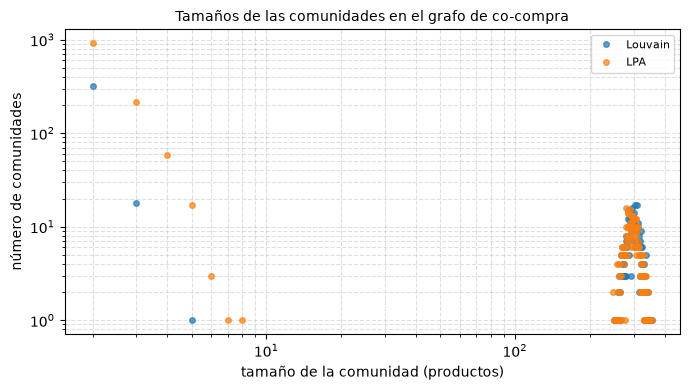

In [23]:
# 10.5 Estabilidad de Louvain y LPA entre semillas
grafo_resenas = GrafoCoCompra.cargar_npz(resenas.RUTA_GRAFO_RESENAS)
est_cocompra = resultados(R / "estabilidad_cocompra.csv",
                          lambda: benchmark.estabilidad_comunidades(grafo, benchmark.SEMILLAS_ESTABILIDAD))
est_resenas = resultados(R / "estabilidad_coresenas.csv",
                         lambda: benchmark.estabilidad_comunidades(grafo_resenas, benchmark.SEMILLAS_ESTABILIDAD[:5]))
resumen_est = (pd.concat([est_cocompra.assign(grafo="co-compra"), est_resenas.assign(grafo="co-reseñas")])
               .groupby(["grafo", "algoritmo"])
               .agg(semillas=("semilla", "count"), comunidades_min=("comunidades", "min"),
                    comunidades_max=("comunidades", "max"), modularidad_media=("modularidad", "mean"),
                    modularidad_std=("modularidad", "std"), nmi_media=("nmi_media", "mean"),
                    ari_media=("ari_media", "mean"), comunidad_max=("comunidad_max", "max"),
                    comunidad_p90=("comunidad_p90", "mean"), segundos_medios=("segundos", "mean")))
display(resumen_est)

# Distribución completa de tamaños de las comunidades en el grafo de co-compra
fig, ax = plt.subplots(figsize=(7, 4))
for col, etiqueta in (("comunidad_louvain", "Louvain"), ("comunidad_lpa", "LPA")):
    valores, conteos = np.unique(com_a[col].value_counts().to_numpy(), return_counts=True)
    ax.loglog(valores, conteos, "o", ms=4, alpha=0.7, label=etiqueta)
ax.set_xlabel("tamaño de la comunidad (productos)"); ax.set_ylabel("número de comunidades")
ax.set_title("Tamaños de las comunidades en el grafo de co-compra", fontsize=10)
ax.grid(True, which="both", linestyle="--", alpha=0.4); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(R / "tamanos_comunidades.png", dpi=150); plt.show()

### Lectura de la auditoría y de la validación

- **10.1.** Louvain devuelve exactamente las 841 componentes conexas del grafo, con $Q = 0.9979$, igual a la de la partición por componentes, y LPA parte algunas componentes hasta llegar a 1 712 comunidades. Louvain no encuentra estructura dentro de las componentes porque cada una es un grupo del generador, densamente conectado y sin aristas hacia afuera.
- **10.2 y 10.3.** La pureza de categoría de Louvain es 0.067, la misma que con las etiquetas permutadas al azar: las comunidades no agrupan productos de la misma categoría. PageRank y el grado ponderado tienen Spearman 0.956 y coinciden en 84 de los 100 primeros productos, como se espera en un grafo no dirigido.
- **10.4.** En el grafo de co-reseñas, Louvain llega a $Q = 0.32$ con 4 272 comunidades, frente a 0.008 de LPA, y su pureza de categoría es 0.106, 1.8 veces la del azar (0.059). Al subir $\gamma$ a 20 la pureza sube a 0.163 con 5 835 comunidades. Con una señal real, Louvain sí encuentra estructura temática y la diferencia con LPA deja de ser trivial.
- **10.5.** En el grafo de co-compra, las 10 semillas de Louvain dan las mismas 841 comunidades (NMI y ARI medios de 1.000) y LPA varía poco (de 1 714 a 1 783 comunidades, NMI 0.997 y ARI 0.993), porque cada componente densa converge a una o pocas etiquetas. Las comunidades de Louvain tienen percentil 90 de 317 productos y máximo de 356, los tamaños de los grupos del generador. En el grafo de co-reseñas la situación se invierte: Louvain cambia mucho entre semillas (de 4 044 a 5 286 comunidades, NMI 0.499 y ARI 0.475) con una modularidad estable (0.321 ± 0.002), señal de muchas particiones casi igual de buenas; LPA es más estable (NMI 0.934 y ARI 0.928) porque casi todo cae en una comunidad gigante de hasta 541 125 de los 579 547 nodos, con $Q = 0.009$. Ahí la distribución de tamaños es muy sesgada: el percentil 90 es de 3 o 4 nodos y la mayor comunidad de Louvain llega a 148 613.

## Resumen de la etapa 8

| Tarea / Algoritmo | Línea base | Complejidad teórica | Resultado principal en datos reales |
| --- | --- | --- | --- |
| **Grafo de co-compra** | Lista de adyacencia de Python | $O(\|V\| + \|E\|)$ en CSR | 150 534 productos, 805 587 aristas, 5.8 MB en disco. La exclusión de las órdenes bloqueadas por la etapa 6 no cambia el grafo: ninguna de las 31 878 tiene dos o más productos (2.3) |
| **PageRank** | Grado ponderado | $O(\|V\| + \|E\|)$ por iteración (SpMV) | Converge en 25 iteraciones; Spearman 0.956 con el grado ponderado y 84 de los 100 primeros en común. 520 ± 6 ms en el grafo completo (100 repeticiones), de 2.5 a 3.9 veces más rápido que NetworkX |
| **Louvain** | Label Propagation (LPA) | ≈ $O(\|E\|)$ por pasada | $Q = 0.9979$, 841 comunidades = exactamente las 841 componentes conexas para todo $\gamma \in [0.5, 20]$; pureza de categoría 0.067, igual al azar (0.067). En el grafo de co-reseñas reales, $Q = 0.32$ y pureza 1.8 veces la del azar |
| **LPA** | Inicialización trivial | $O(k \cdot \|E\|)$ cuasi-lineal | $Q = 0.9959$ en 11 iteraciones; 6 comunidades desconectadas partidas en sus componentes (1 712 comunidades). En el grafo de co-reseñas, $Q = 0.008$ |
| **Estabilidad** | — | $O(\|V\| \log \|V\|)$ por par de particiones | Co-compra: Louvain con NMI y ARI de 1.000 en 10 semillas y LPA con 0.997 y 0.993. Co-reseñas: Louvain con 0.499 y 0.475 en 5 semillas y LPA con 0.934 y 0.928, por una comunidad gigante |

## Referencias

- **Blondel, V. D., Guillaume, J.-L., Lambiotte, R., & Lefebvre, E. (2008).** Fast unfolding of communities in large networks. *Journal of Statistical Mechanics: Theory and Experiment*, 2008(10), P10008.
- **Brin, S., & Page, L. (1998).** The anatomy of a large-scale hypertextual Web search engine. *Computer Networks and ISDN Systems*, 30(1-7), 107-117.
- **Danon, L., Díaz-Guilera, A., Duch, J., & Arenas, A. (2005).** Comparing community structure identification. *Journal of Statistical Mechanics: Theory and Experiment*, 2005(09), P09008.
- **Fortunato, S., & Barthélemy, M. (2007).** Resolution limit in community detection. *Proceedings of the National Academy of Sciences*, 104(1), 36-41.
- **Hagberg, A., Swart, P., & S Chult, D. (2008).** Exploring network structure, dynamics, and function using NetworkX. *Proceedings of the 7th Python in Science Conference (SciPy 2008)*.
- **Hubert, L., & Arabie, P. (1985).** Comparing partitions. *Journal of Classification*, 2(1), 193-218.
- **Newman, M. E. J. (2004).** Fast algorithm for detecting community structure in networks. *Physical Review E*, 69(6), 066133.
- **Newman, M. E. J. (2006).** Modularity and community structure in networks. *Proceedings of the National Academy of Sciences*, 103(23), 8577-8582.
- **Raghavan, U. N., Albert, R., & Kumara, S. (2007).** Near linear time algorithm to detect community structures in large-scale networks. *Physical Review E*, 76(3), 036106.
- **Traag, V. A., Waltman, L., & van Eck, N. J. (2019).** From Louvain to Leiden: guaranteeing well-connected communities. *Scientific Reports*, 9, 5233.